# **EDA indonesian movies**

---



Data = https://drive.google.com/file/d/1uW-rUKjY13UqcTUTeSJDmRSP_QPjR2WF/view?usp=sharing

## IMPORT LIBRARY

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## LOAD DATA

In [ ]:
df = pd.read_csv('/content/indonesian_movies.csv')

## EDA

### Menampilkan Data

In [ ]:
#Menampilkan 5 row teratas
df.head()
#Menampilakan n row teratas
#df.head(10)

#==============================
#Menampilkn 5 row terbawah
#df.tail()

,title,year,description,genre,rating,users_rating,votes,languages,directors,actors,runtime
0,#FriendButMarried 2,2020,Ayudia (Mawar De Jongh) is not satisfied enoug...,Biography,13+,6.5,120,Indonesian,Rako Prijanto,"['Adipati Dolken', 'Mawar Eva de Jongh', 'Vonn...",100 min
1,4 Mantan,2020,"Sara, Airin, Rachel, and Amara were accidental...",Thriller,17+,6.4,8,Indonesian,Hanny Saputra,"['Ranty Maria', 'Jeff Smith', 'Melanie Berentz...",80 min
2,Aku Tahu Kapan Kamu Mati,2020,"After apparent death, Siena is able to see sig...",Horror,13+,5.4,17,Indonesian,Hadrah Daeng Ratu,"['Natasha Wilona', 'Ria Ricis', 'Al Ghazali', ...",92 min
3,Anak Garuda,2020,"Good Morning Indonesia, a school for poor orph...",Adventure,13+,9.1,27,Indonesian,Faozan Rizal,"['Tissa Biani Azzahra', 'Violla Georgie', 'Aji...",129 min
4,Dignitate,2020,Alfi (Al Ghazali) meets Alana (Caitlin Halderm...,Drama,17+,7.6,33,Indonesian,Fajar Nugros,"['Al Ghazali', 'Caitlin Halderman', 'Giorgino ...",109 min


In [ ]:
#Menampilkan summary data frame (nama feature/column, total row data yang tidak null, dan type data) dari data yang diload
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   840 non-null    object 
 3   genre         1236 non-null   object 
 4   rating        376 non-null    object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1265 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       869 non-null    object 
dtypes: float64(1), int64(1), object(9)
memory usage: 109.4+ KB


Berdasarkan summary diatas dapat disimpulkan bahwa:
1. Data terdiri dari **1272 baris** dengan **11 column**
2. Terdapat tiga jenis type data yaitu **float (desimal)**, **integer**, dan object.
3. Column/feature **description**, **genre**, **rating**,  **directors**, dan **runtime** memilik row data yang tidak null kurang dari total row data sehingga dapat kita ketahui pada column tersebut terdapat **Missing**

In [ ]:
#Menampilkan jumlah row dan column data
df.shape

(1272, 11)

### Cek Data Duplikat

In [ ]:
#Cek Data Duplicate
df.duplicated().sum()

0

### Cek Missing Value

In [ ]:
#Cek Missing Value
df.isna().sum()

title             0
year              0
description     432
genre            36
rating          896
users_rating      0
votes             0
languages         0
directors         7
actors            0
runtime         403
dtype: int64

In [ ]:
round(((df.isna().sum())/df.shape[0])*100,2)

title            0.00
year             0.00
description     33.96
genre            2.83
rating          70.44
users_rating     0.00
votes            0.00
languages        0.00
directors        0.55
actors           0.00
runtime         31.68
dtype: float64

In [ ]:
def data_missing(X):
    hasil = pd.DataFrame({
        'Total Data Missing' : X.isna().sum(),
        '%' : round((X.isna().sum()/X.shape[0])*100,2)
    })
    return hasil

In [ ]:
data_missing(df)

,Total Data Missing,%
title,0,0.00
year,0,0.00
description,432,33.96
genre,36,2.83
rating,896,70.44
users_rating,0,0.00
votes,0,0.00
languages,0,0.00
directors,7,0.55
actors,0,0.00


Berdasarkan hasil pengecekan missing value dapat kita ketahui bahwa:
1. Column/feature **description** memiliki **432** row data yang missing (**33,96%**)
2. Column/feature genre memiliki **36** row data yang missing (**2,83%**)
3. Column/feature rating memiliki **896** row data yang missing (**70,44%**)
4. Column/feature directors **7** row data yang missing (**0,55%**)
5. Column/feature runtime 403 row data yang missing (**31,68%**)

In [ ]:
#Menampilkan data-data yang Missing berdasarkan columns
df[df.isna().any(axis=1)]

,title,year,description,genre,rating,users_rating,votes,languages,directors,actors,runtime
5,Guru-Guru Gokil,2020,"When staff salaries get stolen at his school, ...",Comedy,NaN,6.1,153,Indonesian,Sammaria Simanjuntak,"['Gading Marten', 'Boris Bokir', 'Kevin Ardilo...",101 min
16,Surat dari Kematian,2020,Failing to prove the urban legend of Mbak Roha...,Horror,NaN,6.2,5,Indonesian,Hestu Saputra,"['Carissa Perusset', 'Endy Arfian', 'Jerome Ku...",86 min
17,Temen Kondangan,2020,Putri (Prisia Nasution) is challenged to atten...,Comedy,NaN,6.0,11,Indonesian,Iip Sariful Hanan,"['Prisia Nasution', 'Gading Marten', 'Kevin Ju...",86 min
21,#MoveOnAja,2019,"Broke and heartbreak, Irwan just wants to spen...",Comedy,17+,6.3,6,Indonesian,Hestu Saputra,"['Marthino Lio', 'Asmara Abigail', 'Uus', 'Lal...",NaN
49,Hiruk-Pikuk Si Al-Kisah,2019,Siman discovers a foreign crew shooting a moon...,Drama,NaN,6.5,46,Indonesian,Yosep Anggi Noen,"['Gunawan Maryanto', 'Ecky Lamoh', 'Yudi Ahmad...",106 min
...,...,...,...,...,...,...,...,...,...,...,...
1267,The Tiger from Tjampa,1953,"Set in the 1930s, and narrated like a ballad f...",Drama,NaN,6.4,30,Indonesian,D. Djajakusuma,"['Wahid Chan', 'Bambang Hermanto', 'R.D. Ismai...",97 min
1268,Enam Djam di Djogja,1951,Depicting the celebrated recapture of the town...,Drama,NaN,6.3,9,Indonesian,Usmar Ismail,"['R.D. Ismail', 'Del Juzar', 'Aedy Moward', 'A...",116 min
1269,Darah dan Doa,1950,It tells the story of an Indonesian revolution...,Drama,NaN,6.6,27,Indonesian,Usmar Ismail,"['Ella Bergen', 'Faridah', 'R.D. Ismail', 'Del...",150 min
1270,Resia Boroboedoer,1928,NaN,Adventure,NaN,7.0,8,Indonesian,NaN,"['Olive Young', nan, nan, nan, nan, nan, nan, ...",NaN


Berdasarkan hasil diatas dapat kita ketahui bahwa secara keseluruhan terdapat **986** row data yang **missing value**

### Penanganan Missing Value

In [ ]:
#Column/featuere description, directors, dan genre isikan seteiap nilai nan "tidak ada"
df['description'] = df['description'].fillna('tidak ada')
df['directors'] = df['directors'].fillna('tidak ada')
df['genre'] = df['genre'].fillna('tidak ada')

In [ ]:
#Menampilkan data dengan kondisi description 'tidak ada'
df[df['description'] == 'tidak ada']

,title,year,description,genre,rating,users_rating,votes,languages,directors,actors,runtime
121,The Santri,2019,tidak ada,Adventure,NaN,3.9,10,Indonesian,Ken Zheng,"['Azmi Askandar', 'Emil Dardak', 'Wirda Mansur...",NaN
148,Baco Becce,2018,tidak ada,Comedy,13+,8.8,23,Indonesian,Syahrir Arsyad Dini,"['Mimi Peri', 'Syukri Algazali', 'Mamak Ramlah...",87 min
162,Dongeng Mistis,2018,tidak ada,Horror,17+,6.6,22,Indonesian,Orizon Astonia,"['Gandhi Fernando', 'Dhea Ananda', 'Putri Ayud...",88 min
183,Lima,2018,tidak ada,Drama,17+,6.8,36,Indonesian,Harvan Agustriansyah,"['Prisia Nasution', 'Yoga Pratama', 'Baskara M...",NaN
185,Mama Mama Jagoan,2018,tidak ada,Comedy,13+,7.2,11,Indonesian,Sidi Saleh,"['Widyawati', 'Niniek L. Karim', 'Ratna Rianti...",94 min
...,...,...,...,...,...,...,...,...,...,...,...
1257,Wajah Seorang Laki-Laki,1972,tidak ada,Drama,NaN,6.2,6,Indonesian,Teguh Karya,"['Tuti I. Malaon', 'Rima Melati', 'Slamet Raha...",110 min
1258,Malin Kundang,1971,tidak ada,tidak ada,NaN,7.1,7,Indonesian,D. Djajakusuma,"['Noor Azizah', 'M. Budhrasa', 'Darussalam', '...",NaN
1260,Badai Selatan,1962,tidak ada,Drama,NaN,6.3,6,Indonesian,Sofia W.D.,"['W.D. Mochtar', 'Sukarno M. Noor', 'Ida Nursa...",92 min
1270,Resia Boroboedoer,1928,tidak ada,Adventure,NaN,7.0,8,Indonesian,tidak ada,"['Olive Young', nan, nan, nan, nan, nan, nan, ...",NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        376 non-null    object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       869 non-null    object 
dtypes: float64(1), int64(1), object(9)
memory usage: 109.4+ KB


Berdasarkan hasil diatas dapat kita simpulkan bahwa column/feature **description**, **genre**, dan **directors** telah tidak terdapat missing value (**1272 non-null**)

In [ ]:
# rating pakai modus
modus = df['rating'].mode()
df['rating'] = df['rating'].fillna(modus[0])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       869 non-null    object 
dtypes: float64(1), int64(1), object(9)
memory usage: 109.4+ KB


Berdasarkan hasil diatas dapat kita simpulkan bahwa column/feature **rating** telah tidak terdapat missing value (**1272 non-null**)

In [ ]:
# runtime pakai mean
# bersihkan dlu data runtime
df['runtime'] = df['runtime'].replace("min", "", regex=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       869 non-null    object 
dtypes: float64(1), int64(1), object(9)
memory usage: 109.4+ KB


In [ ]:
#Edit type data runtime menjadi numeric
df['runtime'] = pd.to_numeric(df['runtime'], errors='coerce')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       869 non-null    float64
dtypes: float64(2), int64(1), object(8)
memory usage: 109.4+ KB


In [ ]:
df['runtime'] = df['runtime'].fillna(df['runtime'].mean())

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       1272 non-null   float64
dtypes: float64(2), int64(1), object(8)
memory usage: 109.4+ KB


In [ ]:
#Edit type data runtime dari float ke integer
df['runtime'] = df['runtime'].astype(int)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       1272 non-null   int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 109.4+ KB


Berdasarkan hasil diatas dapat kita simpulkan bahwa column/feature **runtime** telah tidak terdapat missing value (**1272 non-null**)

### Feature Engineer

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       1272 non-null   int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 109.4+ KB


In [ ]:
df['votes'].value_counts()

6         58
7         55
11        39
9         39
8         38
          ..
12,507     1
217        1
449        1
1,241      1
154        1
Name: votes, Length: 312, dtype: int64

In [ ]:
df['votes'] = df['votes'].replace(',','.',regex=True) # Mereplace karakter koma menjadi titik
df['votes'].value_counts()

6         58
7         55
11        39
9         39
8         38
          ..
12.507     1
217        1
449        1
1.241      1
154        1
Name: votes, Length: 312, dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   object 
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       1272 non-null   int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 109.4+ KB


In [ ]:
df['votes'] = df['votes'].astype('float64') #conversi dari string ke float terlebih dahulu karena character '.' sebagai tanda desimal
df['votes'] = df['votes'].astype('int64') #conversi dari float ke int

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1272 entries, 0 to 1271
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1272 non-null   object 
 1   year          1272 non-null   int64  
 2   description   1272 non-null   object 
 3   genre         1272 non-null   object 
 4   rating        1272 non-null   object 
 5   users_rating  1272 non-null   float64
 6   votes         1272 non-null   int64  
 7   languages     1272 non-null   object 
 8   directors     1272 non-null   object 
 9   actors        1272 non-null   object 
 10  runtime       1272 non-null   int64  
dtypes: float64(1), int64(3), object(7)
memory usage: 109.4+ KB


In [ ]:
df['year'] = df['year'].astype('object')

### Statistik Deskriptif

In [ ]:
#Melihat statistik deskriptif data bertipe data numerik
#df.describe()
df.describe().T

,count,mean,std,min,25%,50%,75%,max
users_rating,1272.0,6.144418,1.389315,1.2,5.3,6.4,7.1,9.4
votes,1272.0,73.830975,129.770822,1.0,11.0,24.0,65.0,981.0
runtime,1272.0,97.047170,13.322165,45.0,90.0,97.0,100.0,262.0


### Visualisasi Data

In [ ]:
#Menampilkan actors dengan judul 'Wiro Sableng 212'
df[df['title'] == 'Wiro Sableng 212']['actors'].tolist()

["['Vino G. Bastian', 'Yayan Ruhian', 'Fariz Alfarazi', 'Ruth Marini', 'Marsha Timothy', 'Sherina Munaf', 'Marcella Zalianty', 'T. Rifnu Wikana', 'Yusuf Mahardika', 'Aghniny Haque', 'Lukman Sardi', 'Dwi Sasono', 'Happy Salma', 'Marcell Siahaan', 'Restu Triandy']"]

In [ ]:
#Menampilkan data-data pada tahun setelah 2017
df[df['year'] > 2017]

,title,year,description,genre,rating,users_rating,votes,languages,directors,actors,runtime
0,#FriendButMarried 2,2020,Ayudia (Mawar De Jongh) is not satisfied enoug...,Biography,13+,6.5,120,Indonesian,Rako Prijanto,"['Adipati Dolken', 'Mawar Eva de Jongh', 'Vonn...",100
1,4 Mantan,2020,"Sara, Airin, Rachel, and Amara were accidental...",Thriller,17+,6.4,8,Indonesian,Hanny Saputra,"['Ranty Maria', 'Jeff Smith', 'Melanie Berentz...",80
2,Aku Tahu Kapan Kamu Mati,2020,"After apparent death, Siena is able to see sig...",Horror,13+,5.4,17,Indonesian,Hadrah Daeng Ratu,"['Natasha Wilona', 'Ria Ricis', 'Al Ghazali', ...",92
3,Anak Garuda,2020,"Good Morning Indonesia, a school for poor orph...",Adventure,13+,9.1,27,Indonesian,Faozan Rizal,"['Tissa Biani Azzahra', 'Violla Georgie', 'Aji...",129
4,Dignitate,2020,Alfi (Al Ghazali) meets Alana (Caitlin Halderm...,Drama,17+,7.6,33,Indonesian,Fajar Nugros,"['Al Ghazali', 'Caitlin Halderman', 'Giorgino ...",109
...,...,...,...,...,...,...,...,...,...,...,...
223,Tusuk Jelangkung di Lubang Buaya,2018,"Taman Lubang Buaya, famous for its creepiness,...",Horror,13+,2.4,18,Indonesian,Erwin Arnada,"['Nina Kozok', 'Anya Geraldine', 'Rayn Wijaya'...",82
224,Udah Putusin Aja!,2018,A moslem girl is caught being pregnant.,Drama,13+,7.3,11,Indonesian,Rolly Subhandani,"['Rizky Mocil', 'Rana Audi Marissa', 'Billy Da...",88
225,Wahana Rumah Hantu,2018,tidak ada,Adventure,13+,2.8,8,Indonesian,Anto Lupus,"['Renald Ramadhan', 'Adzwa Aurelline', 'Nadira...",115
226,Wiro Sableng 212,2018,"Indonesia, the 16th century, Wiro Sableng, a d...",Action,13+,7.2,1,Indonesian,Angga Dwimas Sasongko,"['Vino G. Bastian', 'Yayan Ruhian', 'Fariz Alf...",123


In [ ]:
#Menampilkan mengetahui genre film pada setelah 2017
df[df['year'] > 2017]['genre'].value_counts()

Drama        80
Horror       63
Comedy       51
Action       13
Adventure    11
Biography     7
Thriller      1
Animation     1
History       1
Name: genre, dtype: int64

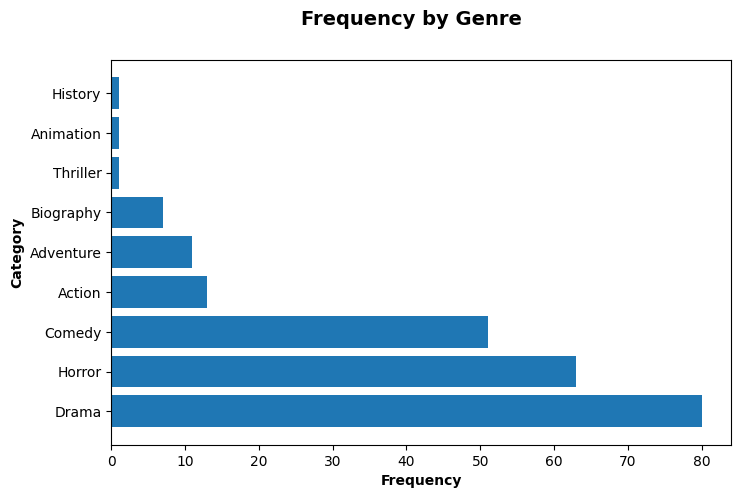

In [ ]:
#sumbu x
frequency = df[df['year'] > 2017]['genre'].value_counts().values
#sumbu y
category = df[df['year'] > 2017]['genre'].value_counts().index

#visualisasi
fig, ax = plt.subplots(figsize = (8, 5)) #Size
fig.suptitle('Frequency by Genre', fontsize = 14, fontweight ="bold") #title
ax.set_ylabel('Category', fontsize = 10, fontweight ="bold") #sb y
ax.set_xlabel('Frequency', fontsize = 10, fontweight ="bold") #sb x
ax.barh(category, frequency) #chart
plt.show()

In [ ]:
# Tampilkan rating yang paling tinggi di 2018
df[df['year'] == 2018].sort_values(by=['users_rating'], ascending=False).head()

,title,year,description,genre,rating,users_rating,votes,languages,directors,actors,runtime
172,Jelita Sejuba: Mencintai Kesatria Negara,2018,"Without dating, Jaka immediately proposes for ...",Drama,13+,9.1,240,Indonesian,Ray Nayoan,"['Putri Marino', 'Wafda Saifan Lubis', 'Alvaro...",97
148,Baco Becce,2018,tidak ada,Comedy,13+,8.8,23,Indonesian,Syahrir Arsyad Dini,"['Mimi Peri', 'Syukri Algazali', 'Mamak Ramlah...",87
136,A Man Called Ahok,2018,Depicts the life of the titular former governo...,Biography,13+,8.7,4,Indonesian,Putrama Tuta,"['Daniel Mananta', 'Kin Wah Chew', 'Eric Febri...",102
204,Serendipity,2018,Rani's life changed drastically after her fath...,Drama,13+,8.5,65,Indonesian,Indra Gunawan,"['Maxime Bouttier', 'Mawar Eva de Jongh', 'Ken...",107
227,Yowis Ben,2018,Bayu falls in love with a girl and decided to ...,Comedy,13+,8.4,3,Indonesian,Fajar Nugros,"['Bayu Skak', 'Cut Meyriska', 'Brandon Salim',...",97


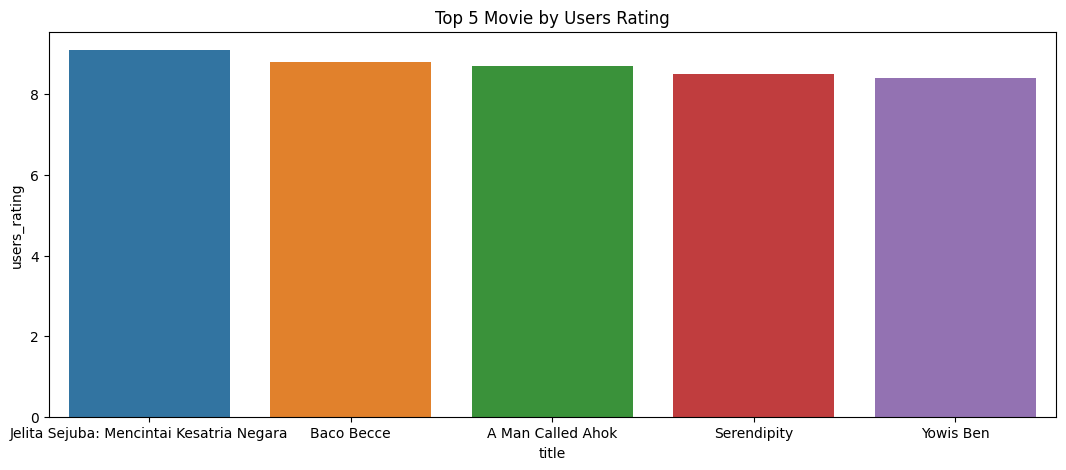

In [ ]:
plt.figure(figsize=(13,5))
plt.title('Top 5 Movie by Users Rating')
sns.barplot(x = 'title',
            y = 'users_rating',
            data = df[df['year'] == 2018].sort_values(by=['users_rating'], ascending=False).head())
plt.show()

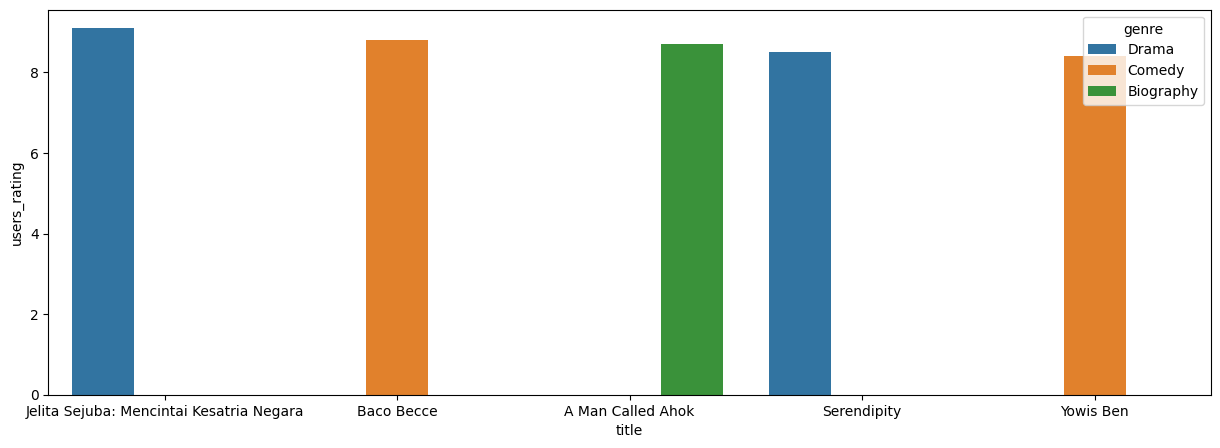

In [ ]:
plt.figure(figsize=(15,5))
sns.barplot(x = 'title',
            y = 'users_rating',
            hue = 'genre',
            data = df[df['year'] == 2018].sort_values(by=['users_rating'], ascending=False).head())
plt.show()

In [ ]:
df[df['year'] == 2018].sort_values(by=['users_rating'], ascending=False).tail()

,title,year,description,genre,rating,users_rating,votes,languages,directors,actors,runtime
220,The Secret: Suster Ngesot Urban Legend,2018,Learning that her father has married a woman h...,Horror,13+,3.5,27,Indonesian,Raffi Ahmad,"['Nagita Slavina', 'Marshanda', 'Raffi Ahmad',...",82
151,Benyamin Biang Kerok,2018,Knowing that their headquarter and residential...,Comedy,17+,2.9,213,Indonesian,Hanung Bramantyo,"['Reza Rahadian', 'Delia Husein', 'Rano Karno'...",97
225,Wahana Rumah Hantu,2018,tidak ada,Adventure,13+,2.8,8,Indonesian,Anto Lupus,"['Renald Ramadhan', 'Adzwa Aurelline', 'Nadira...",115
223,Tusuk Jelangkung di Lubang Buaya,2018,"Taman Lubang Buaya, famous for its creepiness,...",Horror,13+,2.4,18,Indonesian,Erwin Arnada,"['Nina Kozok', 'Anya Geraldine', 'Rayn Wijaya'...",82
167,Hanum & Rangga: Faith & The City,2018,A love story about a dentist's struggle with h...,Drama,13+,1.2,3,Indonesian,Benni Setiawan,"['Acha Septriasa', 'Rio Dewanto', 'Arifin Putr...",90


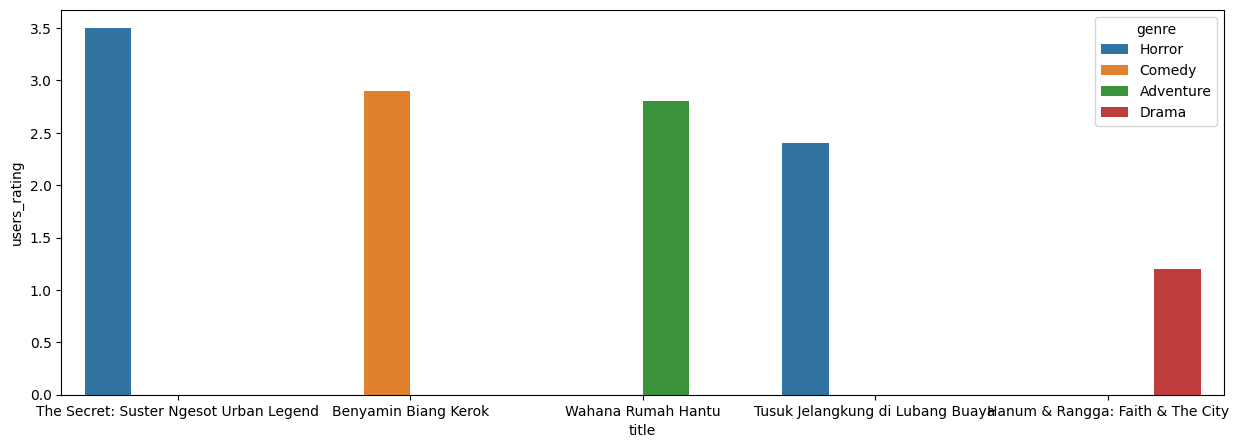

In [ ]:
plt.figure(figsize=(15,5))
sns.barplot(x = 'title',
            y = 'users_riomating',
            hue = 'genre',
            data = df[df['year'] == 2018].sort_values(by=['users_rating'], ascending=False).tail())
plt.show()